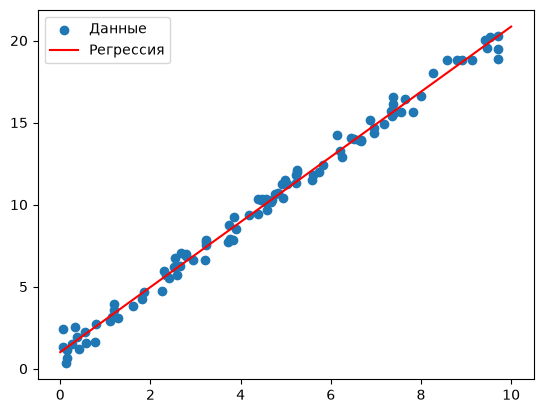

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Данные
X = np.random.rand(100, 1) * 10
y = 2 * X + 1 + np.random.randn(100, 1) * 0.5

# Модель
model = LinearRegression()
model.fit(X, y)

# График
plt.scatter(X, y, label="Данные")
plt.plot([0, 10], model.predict([[0], [10]]), color='red', label="Регрессия")
plt.legend()
plt.show()

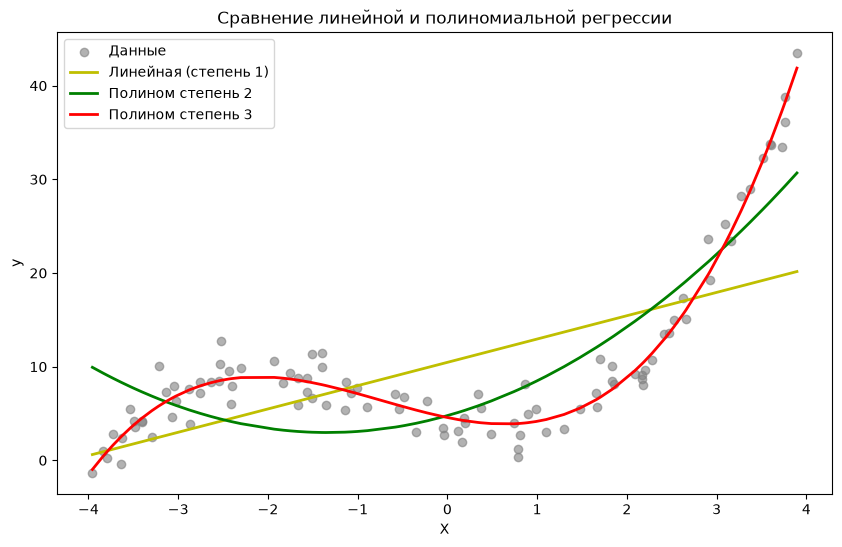

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# --- Данные (немного сложнее, чем раньше) ---
np.random.seed(42)  # чтобы результат был одинаковым при каждом запуске
X = np.random.rand(100, 1) * 8 - 4  # от -4 до 4
y = 0.5 * X**3 + X**2 - 2 * X + 5 + np.random.randn(100, 1) * 2  # кубическая зависимость

# --- Линейная регрессия (для сравнения) ---
linear = LinearRegression()
linear.fit(X, y)
y_pred_linear = linear.predict(X)

# --- Полиномиальная регрессия: степень 2 ---
poly2 = PolynomialFeatures(degree=2)
X_poly2 = poly2.fit_transform(X)
model2 = LinearRegression()
model2.fit(X_poly2, y)
y_pred2 = model2.predict(X_poly2)

# --- Полиномиальная регрессия: степень 3 ---
poly3 = PolynomialFeatures(degree=3)
X_poly3 = poly3.fit_transform(X)
model3 = LinearRegression()
model3.fit(X_poly3, y)
y_pred3 = model3.predict(X_poly3)

# --- Визуализация ---
X_sorted = np.sort(X, axis=0)  # сортируем для красивого графика
y_pred_linear_sorted = linear.predict(X_sorted)
y_pred2_sorted = model2.predict(poly2.transform(X_sorted))
y_pred3_sorted = model3.predict(poly3.transform(X_sorted))

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='gray', alpha=0.6, label='Данные')
plt.plot(X_sorted, y_pred_linear_sorted, 'y-', linewidth=2, label='Линейная (степень 1)')
plt.plot(X_sorted, y_pred2_sorted, 'g-', linewidth=2, label='Полином степень 2')
plt.plot(X_sorted, y_pred3_sorted, 'r-', linewidth=2, label='Полином степень 3')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.title('Сравнение линейной и полиномиальной регрессии')
plt.show()

Линейная регрессия:
  MSE = 40.35
  R²  = 0.4585

Полиномиальная регрессия (степень 2):
  MSE = 32.15
  R²  = 0.5685


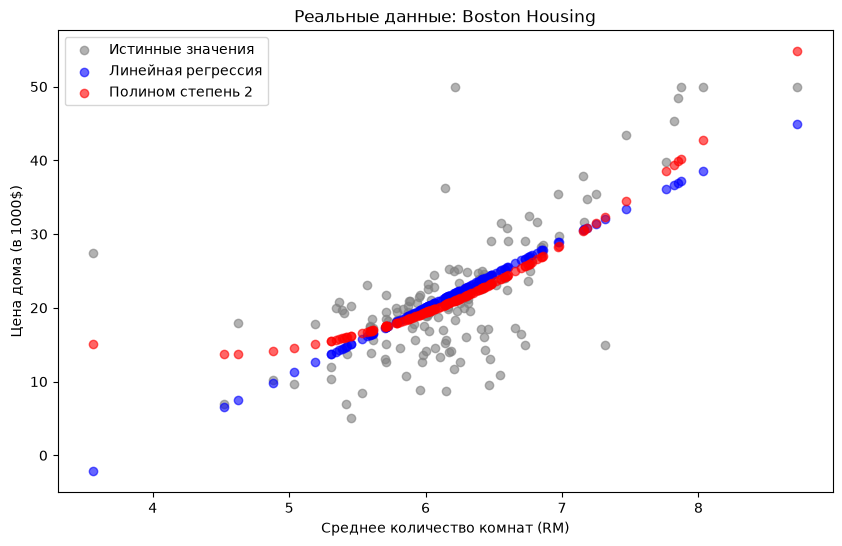

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# --- Загружаем реальные данные (Boston Housing) ---
boston = fetch_openml(data_id=531, as_frame=True)
X = boston.data
y = boston.target

# --- Берём только один признак для наглядности: среднее количество комнат (RM) ---
X_rm = X[['RM']].values

# --- Делим на обучающую и тестовую выборки ---
X_train, X_test, y_train, y_test = train_test_split(X_rm, y, test_size=0.3, random_state=42)

# --- Обучаем линейную регрессию ---
linear = LinearRegression()
linear.fit(X_train, y_train)
y_pred_linear = linear.predict(X_test)

# --- Обучаем полиномиальную регрессию (степень 2) ---
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly)

# --- Метрики для линейной ---
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

# --- Метрики для полиномиальной ---
mse_poly = mean_squared_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

# --- Вывод ---
print("Линейная регрессия:")
print(f"  MSE = {mse_linear:.2f}")
print(f"  R²  = {r2_linear:.4f}")
print("\nПолиномиальная регрессия (степень 2):")
print(f"  MSE = {mse_poly:.2f}")
print(f"  R²  = {r2_poly:.4f}")

# --- График ---
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='gray', alpha=0.6, label='Истинные значения')
plt.scatter(X_test, y_pred_linear, color='blue', alpha=0.6, label='Линейная регрессия')
plt.scatter(X_test, y_pred_poly, color='red', alpha=0.6, label='Полином степень 2')
plt.xlabel('Среднее количество комнат (RM)')
plt.ylabel('Цена дома (в 1000$)')
plt.legend()
plt.title('Реальные данные: Boston Housing')
plt.show()

In [13]:
from sklearn.metrics import mean_squared_error, r2_score

# Допустим, у тебя есть y_true (реальные значения) и y_pred (предсказания)
# Например, возьмём данные из Задачи 2:

# R² — показывает, сколько процентов дисперсии объясняет модель (чем ближе к 1, тем лучше)
r2 = r2_score(y_test, y_pred_poly)
print(f"R² = {r2:.4f}")

# MSE — средняя квадратичная ошибка (чем меньше, тем лучше)
mse = mean_squared_error(y_test, y_pred_poly)
print(f"MSE = {mse:.2f}")

# RMSE — корень из MSE, интерпретируется в единицах целевой переменной
rmse = np.sqrt(mse)
print(f"RMSE = {rmse:.2f}")

R² = 0.5685
MSE = 32.15
RMSE = 5.67


In [14]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Загружаем датасет через sklearn
print("Загружаем данные...")
X, y = fetch_openml("titanic", version=1, as_frame=True, return_X_y=True)
print(f"Данные загружены! Размер: {X.shape}")

# Смотрим, что за колонки у нас есть
print("\nКолонки в данных:")
print(X.columns.tolist())
print("\nПервые 5 строк:")
X.head()

Загружаем данные...
Данные загружены! Размер: (1309, 13)

Колонки в данных:
['pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']

Первые 5 строк:


,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Ссылка на чистый CSV-файл с данными Титаника
url = "https://raw.githubusercontent.com/amueller/scipy-2017-sklearn/091d371/notebooks/datasets/titanic3.csv"

# Загружаем данные прямо из интернета
data = pd.read_csv(url)
print(f"Данные загружены! Размер: {data.shape}")
print("\nПервые 5 строк:")
data.head()

Данные загружены! Размер: (1309, 14)

Первые 5 строк:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [17]:
# Выбираем нужные колонки
features = ['pclass', 'sex', 'age', 'fare']
X = data[features]
y = data['survived']

# Делим на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Определяем числовые и категориальные колонки
numeric_features = ['age', 'fare']
categorical_features = ['pclass', 'sex']

# Создаем пайплайн: заполняем пропуски, масштабируем, кодируем
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
    ])

# Оборачиваем пайплайн в модель
model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('classifier', LogisticRegression(max_iter=1000))])

# Обучаем модель на тренировочных данных
model.fit(X_train, y_train)

# Делаем предсказания на тестовых данных
y_pred = model.predict(X_test)

# Оцениваем точность
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy:.3f}")

# Подробный отчет о том, где модель ошибается
print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred))

NameError: name 'SimpleImputer' is not defined

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer  # ← ЭТОГО НЕ ХВАТАЛО!
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Загружаем данные
url = "https://raw.githubusercontent.com/amueller/scipy-2017-sklearn/091d371/notebooks/datasets/titanic3.csv"
data = pd.read_csv(url)
print(f"Данные загружены! Размер: {data.shape}")

# Выбираем признаки
features = ['pclass', 'sex', 'age', 'fare']
X = data[features]
y = data['survived']

# Делим на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Определяем типы колонок
numeric_features = ['age', 'fare']
categorical_features = ['pclass', 'sex']

# Создаём пайплайн
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

# Модель
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Обучаем
model.fit(X_train, y_train)

# Предсказываем
y_pred = model.predict(X_test)

# Оценка
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy:.3f}")

print("\nОтчёт по классификации:")
print(classification_report(y_test, y_pred))

# Матрица ошибок (чтобы видеть, где модель путается)
print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred))

Данные загружены! Размер: (1309, 14)
Точность модели: 0.775

Отчёт по классификации:
              precision    recall  f1-score   support

           0       0.75      0.89      0.81       144
           1       0.82      0.64      0.72       118

    accuracy                           0.77       262
   macro avg       0.79      0.76      0.77       262
weighted avg       0.78      0.77      0.77       262


Матрица ошибок:
[[128  16]
 [ 43  75]]


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. ЗАГРУЖАЕМ ДАННЫЕ
url = "https://raw.githubusercontent.com/amueller/scipy-2017-sklearn/091d371/notebooks/datasets/titanic3.csv"
data = pd.read_csv(url)

features = ['pclass', 'sex', 'age', 'fare']
X = data[features]
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. ОБРАБОТКА ПРИЗНАКОВ (та же, что и в прошлый раз)
numeric_features = ['age', 'fare']
categorical_features = ['pclass', 'sex']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

# 3. СОЗДАЁМ И ОБУЧАЕМ RANDOM FOREST
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 4. ОБУЧАЕМ ЛОГИСТИЧЕСКУЮ РЕГРЕССИЮ (для сравнения)
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 5. СРАВНИВАЕМ ТОЧНОСТЬ
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Точность Random Forest: {accuracy_rf:.3f}")
print(f"Точность Logistic Regression: {accuracy_lr:.3f}")
print(f"Разница: {accuracy_rf - accuracy_lr:.3f}")

# 6. ОТЧЁТ ПО RANDOM FOREST
print("\n" + "="*50)
print("ОТЧЁТ RANDOM FOREST")
print("="*50)
print(classification_report(y_test, y_pred_rf))
print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred_rf))

# 7. ВАЖНОСТЬ ПРИЗНАКОВ (что самое важное для выживания)
# Получаем названия признаков после one-hot кодирования
feature_names = numeric_features + ['pclass_1', 'pclass_2', 'pclass_3', 'sex_female', 'sex_male']
importances = rf_model.named_steps['classifier'].feature_importances_

print("\n" + "="*50)
print("ВАЖНОСТЬ ПРИЗНАКОВ (что влияет на выживание)")
print("="*50)
for name, imp in sorted(zip(feature_names, importances), key=lambda x: x[1], reverse=True):
    print(f"{name}: {imp:.3f}")

Точность Random Forest: 0.798
Точность Logistic Regression: 0.775
Разница: 0.023

ОТЧЁТ RANDOM FOREST
              precision    recall  f1-score   support

           0       0.76      0.93      0.83       144
           1       0.88      0.64      0.74       118

    accuracy                           0.80       262
   macro avg       0.82      0.78      0.79       262
weighted avg       0.81      0.80      0.79       262

Матрица ошибок:
[[134  10]
 [ 43  75]]

ВАЖНОСТЬ ПРИЗНАКОВ (что влияет на выживание)
fare: 0.275
age: 0.242
sex_male: 0.210
sex_female: 0.157
pclass_3: 0.064
pclass_1: 0.035
pclass_2: 0.018


NameError: name 'Ы' is not defined